## Step 1: Import Libraries and Load Dataset

In [1]:
import pandas as pd

In [2]:
df = pd.read_excel("healthcare_fraud_detection.csv.xlsx")
df

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,...,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m,Fraud_Label
0,P0248,C0009996,66,Male,K21.9,93000,219.73,191.89,Self-Pay,2023-01-04,...,73,Orthopedics,IL,Approved,0,5,Inpatient,0,6.0,Legitimate
1,P0132,C0009983,26,Male,I10,93000,2205.28,1102.67,Self-Pay,2022-04-20,...,74,Neurology,GA,Approved,1,2,Outpatient,1,3.0,Fraud
2,P0286,C0009982,81,Female,I25.10,80053,765.03,738.01,Self-Pay,2023-09-11,...,78,Orthopedics,IL,Approved,0,1,Outpatient,0,3.0,Legitimate
3,P0203,C0009972,80,Male,E78.5,87086,1234.34,1029.42,Self-Pay,2022-08-06,...,66,NaN,NY,Approved,0,3,Outpatient,0,4.0,Legitimate
4,P0077,C0009966,45,Female,K21.9,87086,263.75,217.56,Self-Pay,2021-02-08,...,77,Cardiology,CA,Approved,0,2,Inpatient,0,3.0,Legitimate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,P0166,C0000276,29,Female,E78.5,80053,346.56,331.83,NaN,2024-09-26,...,75,Neurology,CA,Approved,0,0,Emergency,1,2.0,Legitimate
9996,P0018,C0000248,39,Female,I10,36415,332.75,331.76,NaN,2024-04-16,...,77,Cardiology,CA,Approved,0,2,Emergency,0,4.0,Legitimate
9997,P0252,C0000198,54,Male,J06.9,93000,146.08,115.09,NaN,2023-01-23,...,71,Internal Medicine,TX,Approved,0,3,Inpatient,0,6.0,Legitimate
9998,P0263,C0000178,9,Male,J06.9,85025,580.28,370.64,NaN,2023-08-19,...,74,Orthopedics,TX,Rejected,1,5,Inpatient,0,4.0,Fraud


In [3]:
df['Fraud_Label'].value_counts()

Fraud_Label
Legitimate    9171
Fraud          829
Name: count, dtype: int64

In [4]:
excel_file = pd.ExcelFile("healthcare_fraud_detection.csv.xlsx")

excel_file.sheet_names

['Cleaned Data',
 'Network Avg Fraud',
 'Fraud v Legit Claim',
 'Claim Outcomes',
 'Findings']

In [5]:
df = pd.read_excel("healthcare_fraud_detection.csv.xlsx",sheet_name="Cleaned Data")

df.head()

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,...,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m,Fraud_Label
0,P0248,C0009996,66,Male,K21.9,93000,219.73,191.89,Self-Pay,2023-01-04,...,73,Orthopedics,IL,Approved,0,5,Inpatient,0,6.0,Legitimate
1,P0132,C0009983,26,Male,I10,93000,2205.28,1102.67,Self-Pay,2022-04-20,...,74,Neurology,GA,Approved,1,2,Outpatient,1,3.0,Fraud
2,P0286,C0009982,81,Female,I25.10,80053,765.03,738.01,Self-Pay,2023-09-11,...,78,Orthopedics,IL,Approved,0,1,Outpatient,0,3.0,Legitimate
3,P0203,C0009972,80,Male,E78.5,87086,1234.34,1029.42,Self-Pay,2022-08-06,...,66,NaN,NY,Approved,0,3,Outpatient,0,4.0,Legitimate
4,P0077,C0009966,45,Female,K21.9,87086,263.75,217.56,Self-Pay,2021-02-08,...,77,Cardiology,CA,Approved,0,2,Inpatient,0,3.0,Legitimate


### This displays all available sheets.

 : Then we'll inspect the main data sheet and decide which one is appropriate for our project.

### Why does your Excel file have multiple sheets?
- Cleaned Data: Contains the main claim records.
- Network Avg Fraud: Contains summary information about fraud patterns.
- Fraud v Legit Claim: Contains comparisons between fraudulent and legitimate claims.
- Claim Outcomes: Contains claim outcome summaries.
- Findings: Contains summarized observations.
  

## Step 2: Initial Data Inspection

In [6]:
df.shape

(10000, 21)

In [7]:
pd.crosstab(df['Is_Fraud'], df['Fraud_Label'])

Fraud_Label,Fraud,Legitimate
Is_Fraud,,
0,0,9171
1,829,0


In [8]:
df.columns

Index(['Provider_ID', 'Claim_ID', 'Patient_Age', 'Patient_Gender',
       'Diagnosis_Code', 'Procedure_Code', 'Claim_Amount', 'Approved_Amount',
       'Insurance_Type', 'Claim_Submission_Date',
       'Days_Between_Service_and_Claim',
       'Number_of_Claims_Per_Provider_Monthly', 'Provider_Specialty',
       'Patient_State', 'Claim_Status', 'Is_Fraud', 'Length_of_Stay',
       'Visit_Type', 'Chronic_Condition_Flag', 'Prior_Visits_12m',
       'Fraud_Label'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Provider_ID                            10000 non-null  object        
 1   Claim_ID                               10000 non-null  object        
 2   Patient_Age                            10000 non-null  int64         
 3   Patient_Gender                         10000 non-null  object        
 4   Diagnosis_Code                         10000 non-null  object        
 5   Procedure_Code                         10000 non-null  int64         
 6   Claim_Amount                           10000 non-null  float64       
 7   Approved_Amount                        10000 non-null  float64       
 8   Insurance_Type                         9650 non-null   object        
 9   Claim_Submission_Date                  10000 non-null  datetim

In [10]:
df.isnull().sum()   

Provider_ID                                0
Claim_ID                                   0
Patient_Age                                0
Patient_Gender                             0
Diagnosis_Code                             0
Procedure_Code                             0
Claim_Amount                               0
Approved_Amount                            0
Insurance_Type                           350
Claim_Submission_Date                      0
Days_Between_Service_and_Claim             0
Number_of_Claims_Per_Provider_Monthly      0
Provider_Specialty                       350
Patient_State                              0
Claim_Status                               0
Is_Fraud                                   0
Length_of_Stay                             0
Visit_Type                                 0
Chronic_Condition_Flag                     0
Prior_Visits_12m                         350
Fraud_Label                                0
dtype: int64

In [11]:
df.isnull().sum().sum() #The second command shows the total missing cells

np.int64(1050)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df['Claim_ID'].duplicated().sum()  # This checks whether any claim IDs are repeated.

np.int64(0)

In [14]:
categorical_columns = ['Patient_Gender','Insurance_Type', 'Provider_Specialty','Claim_Status','Visit_Type','Patient_State','Diagnosis_Code','Fraud_Label']

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Patient_Gender:
['Male' 'Female']

Insurance_Type:
['Self-Pay' 'Private' 'Medicare' 'Medicaid' nan]

Provider_Specialty:
['Orthopedics' 'Neurology' nan 'Cardiology' 'General Practice'
 'Pulmonology' 'Internal Medicine']

Claim_Status:
['Approved' 'Pending' 'Rejected']

Visit_Type:
['Inpatient' 'Outpatient' 'Emergency']

Patient_State:
['IL' 'GA' 'NY' 'CA' 'OH' 'FL' 'TX' 'PA']

Diagnosis_Code:
['K21.9' 'I10' 'I25.10' 'E78.5' 'J18.9' 'E11.9' 'F41.9' 'N39.0' 'J06.9'
 'M54.5']

Fraud_Label:
['Legitimate' 'Fraud']


In [15]:
df.describe() # Now we need to understand the numerical columns, their average, minimum, maximum and distribution.

,Patient_Age,Procedure_Code,Claim_Amount,Approved_Amount,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Is_Fraud,Length_of_Stay,Chronic_Condition_Flag,Prior_Visits_12m
count,10000.000000,10000.00000,10000.000000,10000.000000,10000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,9650.000000
mean,49.755000,86905.21170,572.804406,475.514157,2023-01-10 02:13:12,14.413800,68.628000,0.082900,2.19930,0.292000,3.026425
min,1.000000,36415.00000,60.210000,50.350000,2021-01-06 00:00:00,0.000000,42.000000,0.000000,0.00000,0.000000,0.000000
25%,37.750000,80053.00000,305.205000,257.200000,2022-01-13 00:00:00,7.000000,60.000000,0.000000,1.00000,0.000000,2.000000
50%,50.000000,93000.00000,461.225000,388.370000,2023-01-03 00:00:00,14.000000,66.000000,0.000000,2.00000,0.000000,3.000000
75%,62.000000,99213.00000,711.365000,598.347500,2024-01-05 00:00:00,22.000000,72.000000,0.000000,3.00000,1.000000,4.000000
max,95.000000,99214.00000,6590.700000,4270.890000,2025-01-26 00:00:00,29.000000,144.000000,1.000000,5.00000,1.000000,12.000000
std,17.910144,14965.32496,406.202437,323.257165,NaN,8.489875,14.905872,0.275745,1.71046,0.454705,1.722789


### Next task: Check whether both fraud columns match

We need to compare:
- Is_Fraud – numeric values (0 and 1).
- Fraud_Label – text values (Legitimate and Fraud).

In [16]:
pd.crosstab(df['Is_Fraud'], df['Fraud_Label'])

Fraud_Label,Fraud,Legitimate
Is_Fraud,,
0,0,9171
1,829,0


Is_Fraud = 0 represents Legitimate claims.



Is_Fraud = 1 represents Fraud claims.



Both columns match perfectly.



There are no conflicting labels.

## Step 3: Exploratory Data Analysis (EDA)
### Next step – Check outliers

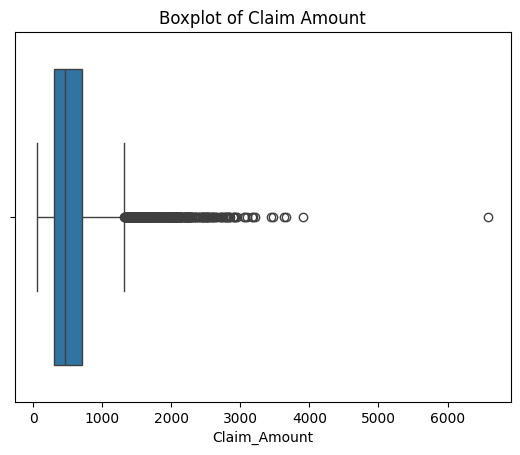

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df['Claim_Amount'])
plt.title('Boxplot of Claim Amount')
plt.show()

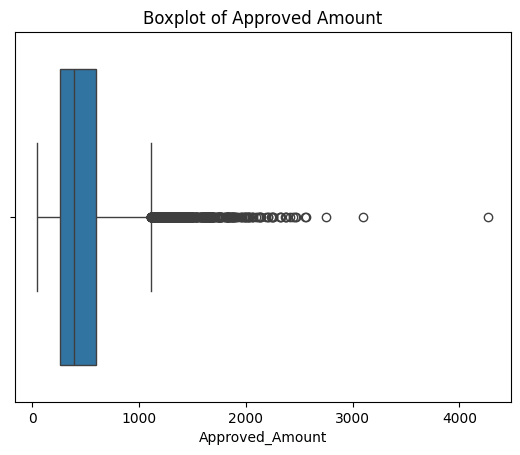

In [18]:
sns.boxplot(x=df['Approved_Amount'])
plt.title('Boxplot of Approved Amount')
plt.show()

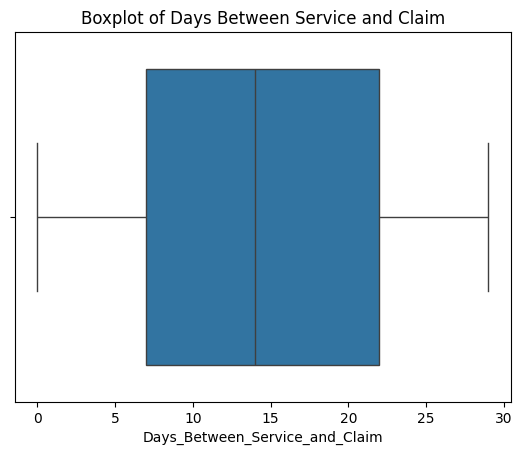

In [19]:
sns.boxplot(x=df['Days_Between_Service_and_Claim'])   #Purpose: To identify unusually high or low numbers of days between the medical service and claim submission.
plt.title('Boxplot of Days Between Service and Claim')
plt.show()

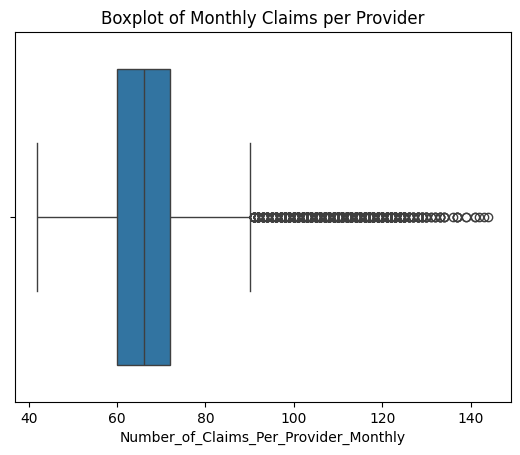

In [20]:
sns.boxplot(x=df['Number_of_Claims_Per_Provider_Monthly'])  #Purpose: To identify providers with unusually high monthly claim counts.
plt.title('Boxplot of Monthly Claims per Provider')
plt.show()

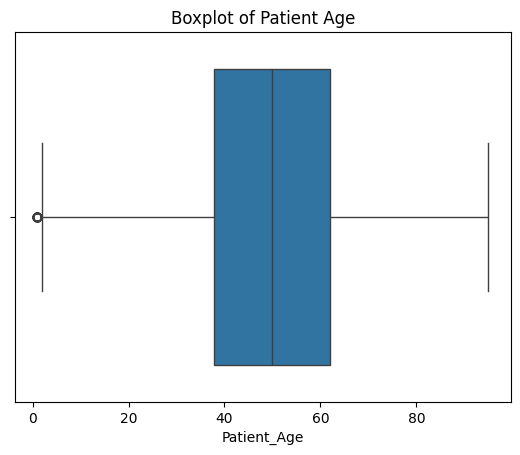

In [21]:
sns.boxplot(x=df['Patient_Age'])
plt.title('Boxplot of Patient Age')
plt.show()

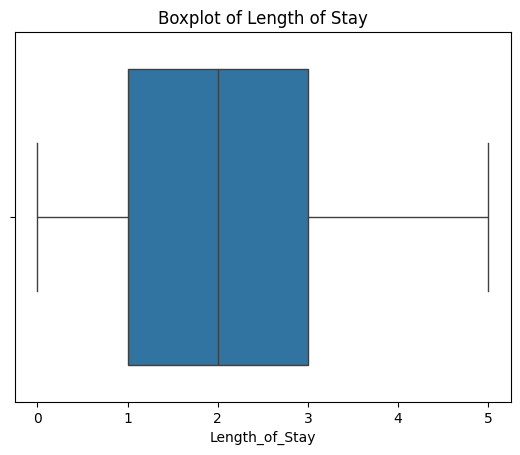

In [22]:
sns.boxplot(x=df['Length_of_Stay'])
plt.title('Boxplot of Length of Stay')
plt.show()

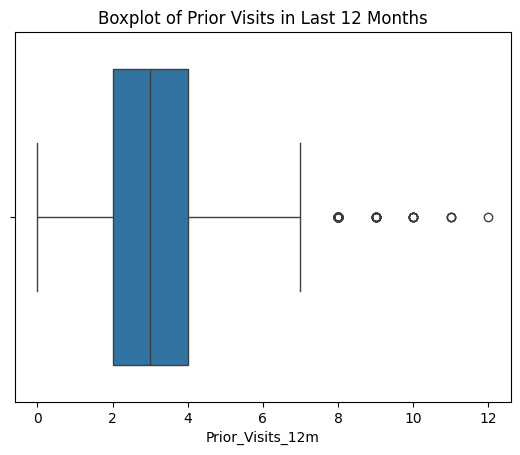

In [23]:
sns.boxplot(x=df['Prior_Visits_12m'])
plt.title('Boxplot of Prior Visits in Last 12 Months')
plt.show()

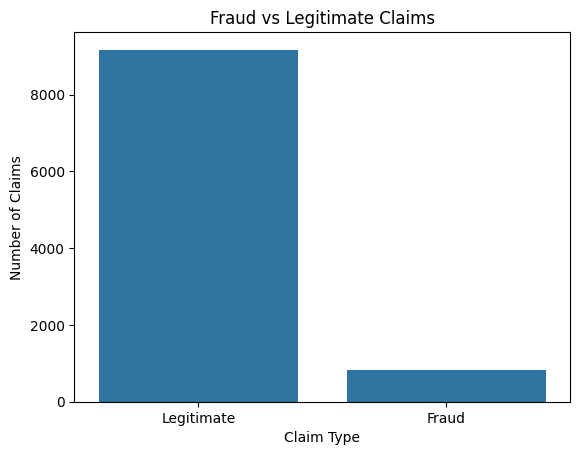

In [24]:
sns.countplot(data=df, x='Fraud_Label')

plt.title('Fraud vs Legitimate Claims')
plt.xlabel('Claim Type')
plt.ylabel('Number of Claims')

plt.show()

### EDA Insight:

The graph shows that legitimate claims are much higher than fraudulent claims. Only a small proportion of claims are fraudulent, indicating a highly imbalanced dataset. This imbalance should be considered during model building to improve fraud detection performance.

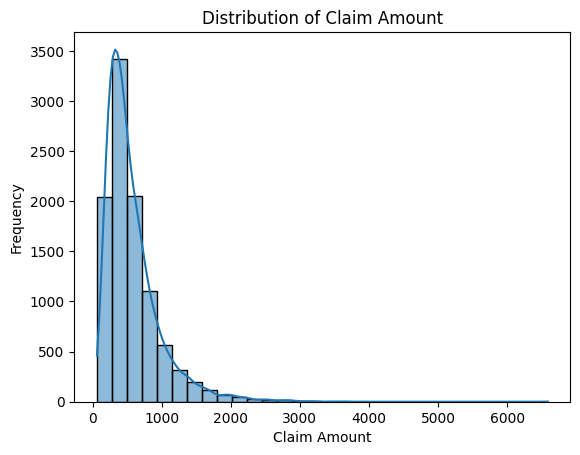

In [25]:
sns.histplot(data=df, x='Claim_Amount', bins=30, kde=True)

plt.title('Distribution of Claim Amount')
plt.xlabel('Claim Amount')
plt.ylabel('Frequency')

plt.show()

### Insight:
- Most healthcare claims have relatively low claim amounts.
- The distribution is positively (right) skewed.
- High-value claims are comparatively rare.
- A few extreme values may indicate potential outliers.
- Claim amount may be an important feature for identifying unusual claim patterns.
    
Key finding: Claim amounts are not normally distributed. High-value claims should be examined along with other features to identify potentially suspicious claims.

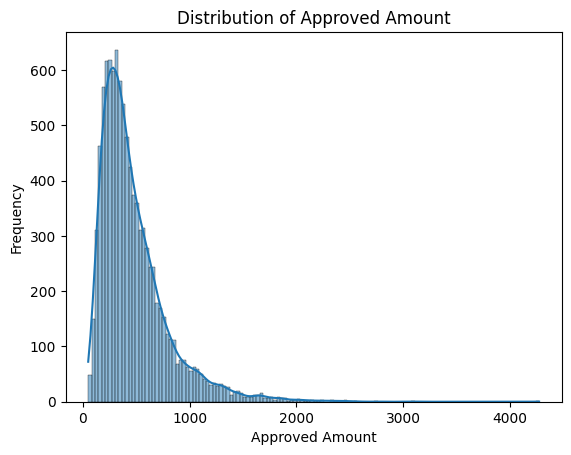

In [26]:
sns.histplot(df['Approved_Amount'], kde=True)
plt.title('Distribution of Approved Amount')
plt.xlabel('Approved Amount')
plt.ylabel('Frequency')
plt.show()

### Insight:

The approved amount distribution is strongly positively skewed, with most approved amounts concentrated in the lower range, particularly around 200–700. The frequency decreases as the approved amount increases, with only a small number of claims having very high approved amounts. The long right tail indicates the presence of extreme values, which may be potential outliers. Therefore, approved amount is an important variable to examine when identifying unusual claim patterns related to healthcare fraud.

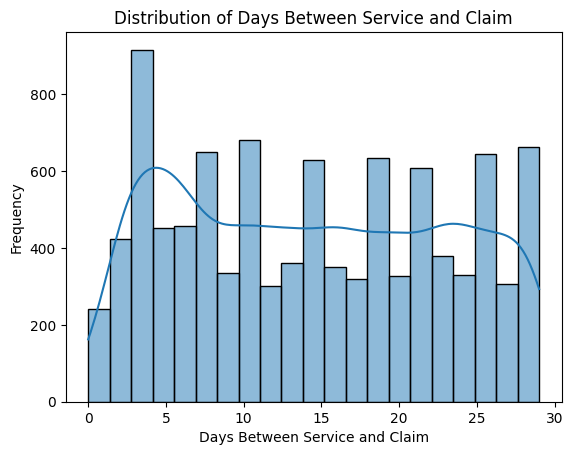

In [27]:
sns.histplot(df['Days_Between_Service_and_Claim'], kde=True)
plt.title('Distribution of Days Between Service and Claim')
plt.xlabel('Days Between Service and Claim')
plt.ylabel('Frequency')
plt.show()

### Insight:

The number of days between service and claim is distributed across a range of approximately 0 to 30 days, with claims occurring throughout this period. The highest frequency is observed around 4 days, while several other days also show relatively high frequencies. Unlike the claim amount variables, this distribution does not show strong right skewness or extreme values. The variation in claim submission timing may be useful for identifying unusual claim patterns when combined with other fraud-related features.

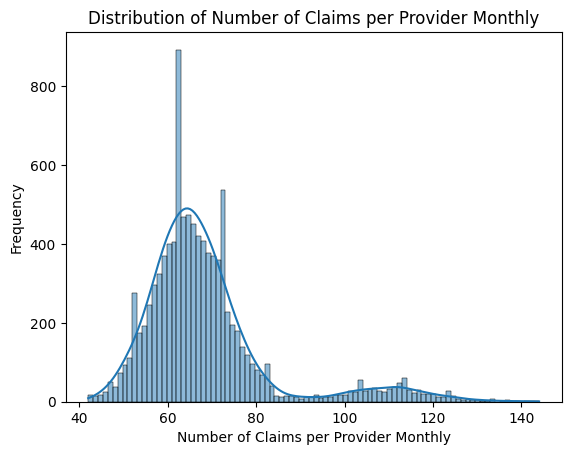

In [28]:
sns.histplot(df['Number_of_Claims_Per_Provider_Monthly'], kde=True)

plt.title('Distribution of Number of Claims per Provider Monthly')
plt.xlabel('Number of Claims per Provider Monthly')
plt.ylabel('Frequency')

plt.show()

### Insight:

The histogram shows a positively skewed distribution of monthly claims per provider. Most providers handle approximately 50–80 claims per month, with the highest frequency around 60–65 claims. A smaller number of providers handle higher claim volumes, approximately 100–120 claims per month. This indicates variations in monthly claim volume among providers. Providers with unusually high claim volumes may require further investigation, as this pattern could be associated with potentially suspicious claim activity. However, high claim volume alone does not confirm fraud.

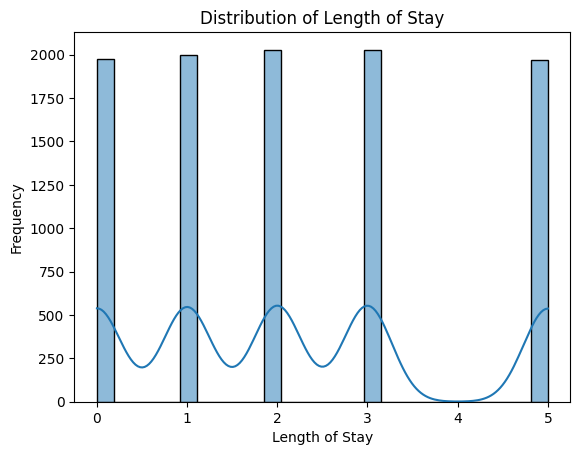

In [29]:
sns.histplot(df['Length_of_Stay'], kde=True)

plt.title('Distribution of Length of Stay')
plt.xlabel('Length of Stay')
plt.ylabel('Frequency')

plt.show()

### Insight:

The graph shows the distribution of patients' length of stay. Most observations are concentrated at 0, 1, 2, 3, and 5 days, with approximately similar frequencies. Very few or almost no observations are recorded for 4 days. This indicates that patient stays are concentrated around specific whole-day durations. The reason for the low frequency of 4-day stays may require further investigation.



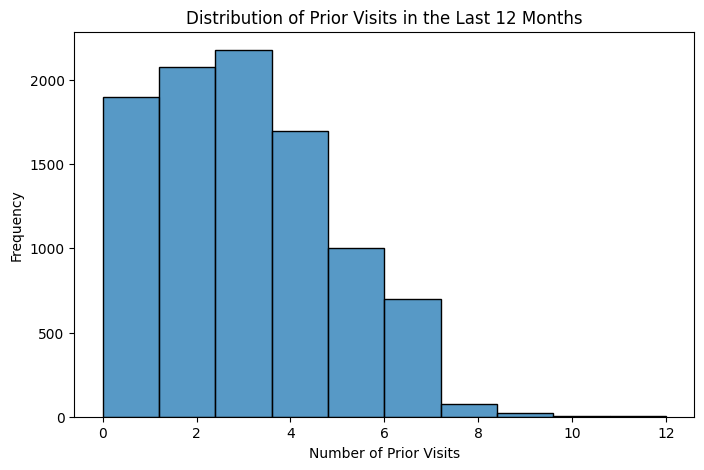

In [30]:
plt.figure(figsize=(8,5))
sns.histplot(df['Prior_Visits_12m'].dropna(), bins=10, kde=False)

plt.title('Distribution of Prior Visits in the Last 12 Months')
plt.xlabel('Number of Prior Visits')
plt.ylabel('Frequency')

plt.show()

### Insight:

The graph shows a positively skewed (right-skewed) distribution of prior visits in the last 12 months. Most patients have approximately 1–3 prior visits, with the highest frequency around 3 visits. The frequency gradually decreases as the number of visits increases, and very few patients have more than 7 visits. This indicates that most patients have relatively fewer previous visits, while a small group has frequent healthcare visits.



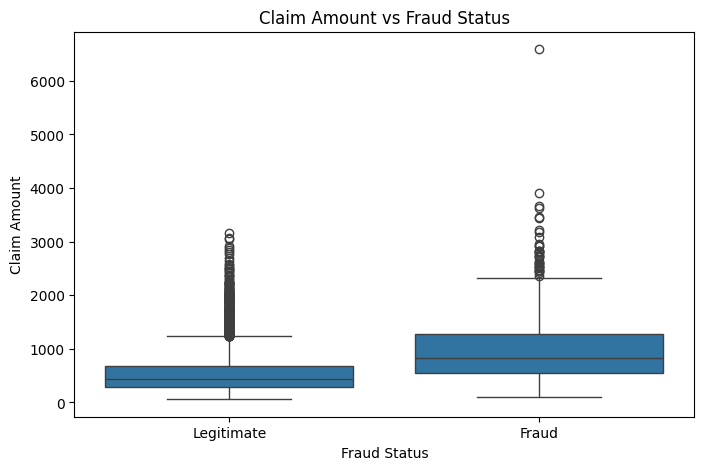

In [31]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Fraud_Label', y='Claim_Amount', data=df)

plt.title('Claim Amount vs Fraud Status')
plt.xlabel('Fraud Status')
plt.ylabel('Claim Amount')

plt.show()

### Insight:

The box plot shows that fraudulent claims generally have higher claim amounts than legitimate claims. The median claim amount and interquartile range are higher for fraudulent claims, indicating greater variation in claim values. Both categories contain several high-value outliers, with the fraud category showing an extreme outlier above 6,000. This suggests that higher claim amounts may be associated with fraudulent activity, although claim amount alone cannot confirm fraud.

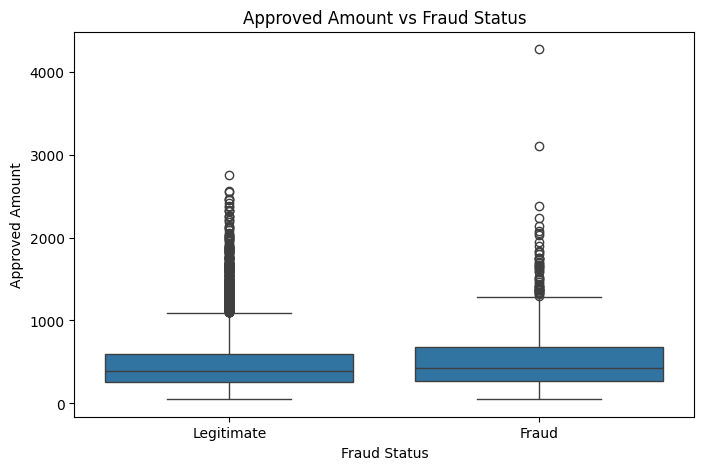

In [32]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Fraud_Label', y='Approved_Amount', data=df)

plt.title('Approved Amount vs Fraud Status')
plt.xlabel('Fraud Status')
plt.ylabel('Approved Amount')

plt.show()

### Insight:

The box plot shows that legitimate and fraudulent claims have relatively similar approved amount distributions. However, fraudulent claims contain some extreme high-value outliers, reaching above 4,000. Legitimate claims also show several high-value outliers. This indicates that unusually high approved amounts may be associated with potential fraudulent activity, but approved amount alone is not sufficient to identify fraud.

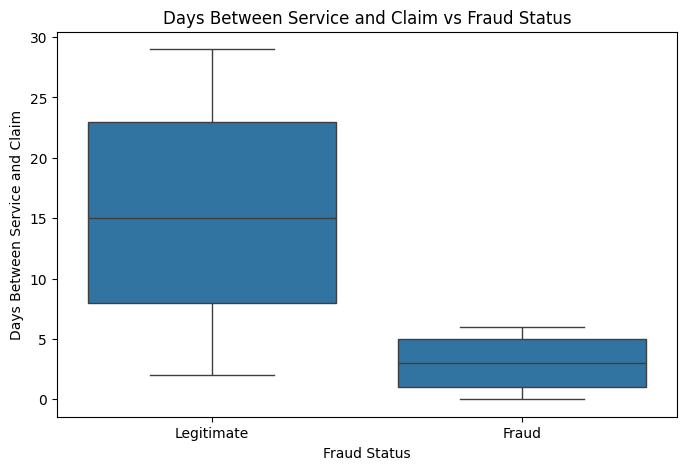

In [33]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Fraud_Label', y='Days_Between_Service_and_Claim', data=df)

plt.title('Days Between Service and Claim vs Fraud Status')
plt.xlabel('Fraud Status')
plt.ylabel('Days Between Service and Claim')

plt.show()

### Insight:

The box plot shows a significant difference in the number of days between service and claim submission. Legitimate claims have a higher median delay of approximately 15 days, whereas fraudulent claims have a much shorter median delay of around 2 days. This indicates that fraudulent claims in this dataset are generally submitted shortly after the service date, making shorter claim submission delays a potential indicator of fraudulent activity.

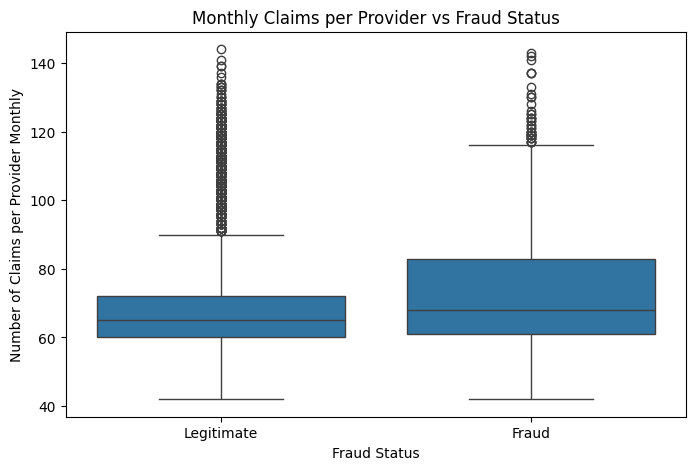

In [34]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Fraud_Label',
            y='Number_of_Claims_Per_Provider_Monthly',
            data=df)

plt.title('Monthly Claims per Provider vs Fraud Status')
plt.xlabel('Fraud Status')
plt.ylabel('Number of Claims per Provider Monthly')

plt.show()

### Insight:

The box plot shows that fraudulent claims generally have a slightly higher median number of monthly claims per provider than legitimate claims. The fraud group also has a wider interquartile range, indicating greater variation in monthly claim volume. Both groups contain several high-value outliers, with some providers having very high monthly claim counts. This suggests that unusually high provider claim activity may be associated with fraud and could be useful for further analysis.


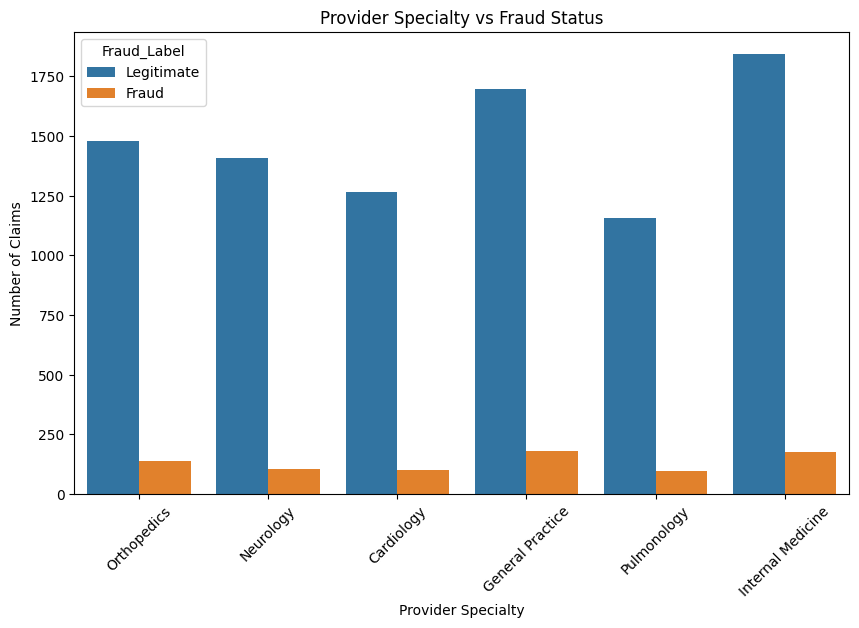

In [35]:
plt.figure(figsize=(10,6))

sns.countplot(data=df, x='Provider_Specialty', hue='Fraud_Label')

plt.title('Provider Specialty vs Fraud Status')
plt.xlabel('Provider Specialty')
plt.ylabel('Number of Claims')
plt.xticks(rotation=45)

plt.show()

### Insight:

The chart shows that fraudulent claims are present across all provider specialties. General Practice and Internal Medicine have the highest numbers of fraudulent claims, while Orthopedics and Neurology have relatively fewer. However, the number of legitimate claims is much higher than fraudulent claims in every specialty, so the differences in raw counts should be interpreted with the overall class imbalance in mind.

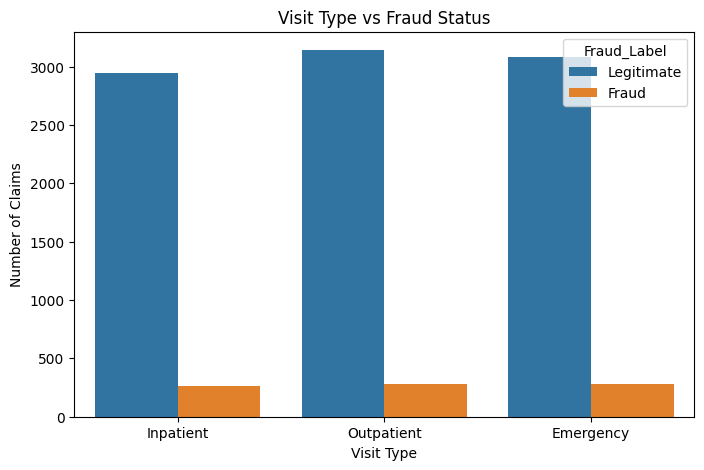

In [36]:
plt.figure(figsize=(8,5))

sns.countplot(x='Visit_Type', hue='Fraud_Label', data=df)

plt.title('Visit Type vs Fraud Status')
plt.xlabel('Visit Type')
plt.ylabel('Number of Claims')

plt.show()

### Insight:

The number of legitimate claims is much higher than fraudulent claims across all three visit types. Among the visit types, Inpatient and Outpatient visits show slightly higher numbers of fraudulent claims than Emergency visits. Overall, fraud is present in every visit type, but there is no clear evidence from this chart alone that a particular visit type is strongly associated with fraud.

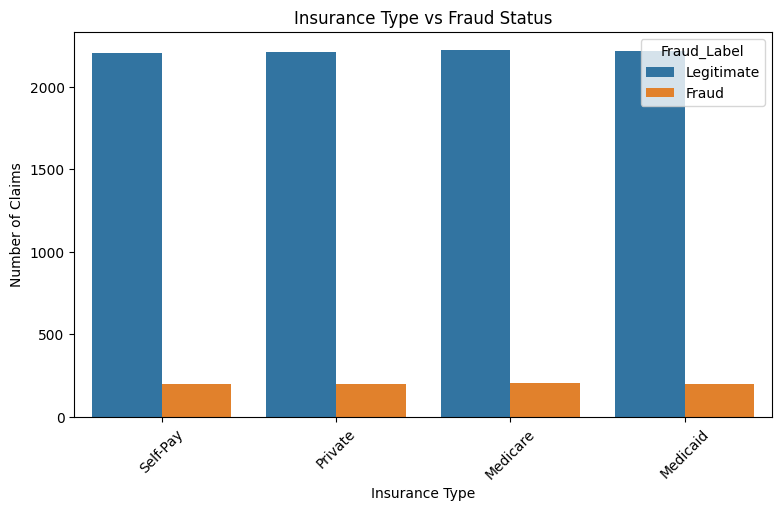

In [37]:

plt.figure(figsize=(9,5))

sns.countplot(x='Insurance_Type', hue='Fraud_Label', data=df)

plt.title('Insurance Type vs Fraud Status')
plt.xlabel('Insurance Type')
plt.ylabel('Number of Claims')

plt.xticks(rotation=45)
plt.show()

### Insight:

Fraudulent claims are present across all insurance types. Self-Pay and Private insurance show slightly higher numbers of fraudulent claims, while Medicaid has the lowest. However, the overall number of legitimate claims is much higher than fraudulent claims in every insurance category. This suggests that insurance type alone does not strongly distinguish fraudulent claims.

# Exploratory Data Analysis (EDA) – Summary

The dataset contains 10,000 records and 21 columns related to healthcare insurance claims.

1. **Dataset Overview:** The dataset contains numerical and categorical features related to patients, healthcare providers, claim amounts and claim details.

2. **Missing Values:** Three columns — `Insurance_Type`, `Provider_Specialty` and `Prior_Visits_12m` — contain 350 missing values each.

3. **Duplicate Values:** No duplicate records or duplicate `Claim_ID` values were found.

4. **Target Distribution:** The dataset contains 9,171 legitimate claims (91.71%) and 829 fraudulent claims (8.29%), indicating class imbalance.

5. **Claim Amount:** Claim amounts are positively skewed, with a small number of high-value claims. Fraudulent claims show a higher median claim amount in the observed data.

6. **Approved Amount:** Approved amounts are also positively skewed, with some extreme values. Both legitimate and fraudulent claims contain high-value outliers.

7. **Claim Submission Delay:** Fraudulent claims show a shorter median submission delay than legitimate claims in this dataset.

8. **Other Numerical Features:** Length of stay and prior visits show variations in patient-related patterns.

9. **Categorical Features:** Bar plots comparing Provider Specialty, Visit Type and Insurance Type with fraud status help explore differences in fraud and legitimate claim counts across categories.

10. **Fraud-Related Observations:** The visualizations reveal differences between legitimate and fraudulent claims in certain numerical and categorical features. These patterns may help identify potentially suspicious claims.

**Conclusion:** EDA helped identify missing values, class imbalance, unusual observations and potential relationships between features and fraud status. These findings will guide the data preprocessing and model-building stages.

## Step 4 – Preprocessing and Feature Engineering

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Provider_ID                            10000 non-null  object        
 1   Claim_ID                               10000 non-null  object        
 2   Patient_Age                            10000 non-null  int64         
 3   Patient_Gender                         10000 non-null  object        
 4   Diagnosis_Code                         10000 non-null  object        
 5   Procedure_Code                         10000 non-null  int64         
 6   Claim_Amount                           10000 non-null  float64       
 7   Approved_Amount                        10000 non-null  float64       
 8   Insurance_Type                         9650 non-null   object        
 9   Claim_Submission_Date                  10000 non-null  datetim

In [39]:
y = df['Is_Fraud']
y

0       0
1       1
2       0
3       0
4       0
       ..
9995    0
9996    0
9997    0
9998    1
9999    1
Name: Is_Fraud, Length: 10000, dtype: int64

In [40]:
y.value_counts()

Is_Fraud
0    9171
1     829
Name: count, dtype: int64

In [41]:
X = df.drop(columns=['Is_Fraud', 'Fraud_Label','Claim_ID','Provider_ID','Approved_Amount','Claim_Status'])
X

,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,66,Male,K21.9,93000,219.73,Self-Pay,2023-01-04,6,73,Orthopedics,IL,5,Inpatient,0,6.0
1,26,Male,I10,93000,2205.28,Self-Pay,2022-04-20,5,74,Neurology,GA,2,Outpatient,1,3.0
2,81,Female,I25.10,80053,765.03,Self-Pay,2023-09-11,14,78,Orthopedics,IL,1,Outpatient,0,3.0
3,80,Male,E78.5,87086,1234.34,Self-Pay,2022-08-06,28,66,NaN,NY,3,Outpatient,0,4.0
4,45,Female,K21.9,87086,263.75,Self-Pay,2021-02-08,10,77,Cardiology,CA,2,Inpatient,0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,29,Female,E78.5,80053,346.56,NaN,2024-09-26,16,75,Neurology,CA,0,Emergency,1,2.0
9996,39,Female,I10,36415,332.75,NaN,2024-04-16,8,77,Cardiology,CA,2,Emergency,0,4.0
9997,54,Male,J06.9,93000,146.08,NaN,2023-01-23,6,71,Internal Medicine,TX,3,Inpatient,0,6.0
9998,9,Male,J06.9,85025,580.28,NaN,2023-08-19,1,74,Orthopedics,TX,5,Inpatient,0,4.0


In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2, random_state=42,stratify=y)

In [43]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 15)
X_test: (2000, 15)
y_train: (8000,)
y_test: (2000,)


In [44]:
# Missing Value Handling

X_train.isnull().sum()

Patient_Age                                0
Patient_Gender                             0
Diagnosis_Code                             0
Procedure_Code                             0
Claim_Amount                               0
Insurance_Type                           284
Claim_Submission_Date                      0
Days_Between_Service_and_Claim             0
Number_of_Claims_Per_Provider_Monthly      0
Provider_Specialty                       283
Patient_State                              0
Length_of_Stay                             0
Visit_Type                                 0
Chronic_Condition_Flag                     0
Prior_Visits_12m                         282
dtype: int64

In [45]:
X_train['Prior_Visits_12m'].describe()  # Before applying anything, let's inspect the numerical column's distribution.

count    7718.000000
mean        3.004405
std         1.721426
min         0.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        12.000000
Name: Prior_Visits_12m, dtype: float64

In [46]:
# Next: Calculate the median from training data

X_train['Prior_Visits_12m'].median()

np.float64(3.0)

In [47]:
print(X_train['Insurance_Type'].mode()[0])

print(X_train['Provider_Specialty'].mode()[0])

Medicare
Internal Medicine


In [48]:
# Fill categorical missing values

X_train['Insurance_Type'] = X_train['Insurance_Type'].fillna('Medicare')
X_test['Insurance_Type'] = X_test['Insurance_Type'].fillna('Medicare')

X_train['Provider_Specialty'] = X_train['Provider_Specialty'].fillna('Internal Medicine')
X_test['Provider_Specialty'] = X_test['Provider_Specialty'].fillna('Internal Medicine')


In [49]:
# Fill numerical missing values

X_train['Prior_Visits_12m'] = X_train['Prior_Visits_12m'].fillna(3.0)
X_test['Prior_Visits_12m'] = X_test['Prior_Visits_12m'].fillna(3.0)

We use 3.0 to fill the missing values in the Prior_Visits_12m column.

From our earlier analysis:
- Mean = 3.004
- Median = 3.0
- Missing values = 282

In [50]:
print("Training missing values:")
print(X_train.isnull().sum())

print("Testing missing values:")
print(X_test.isnull().sum())

Training missing values:
Patient_Age                              0
Patient_Gender                           0
Diagnosis_Code                           0
Procedure_Code                           0
Claim_Amount                             0
Insurance_Type                           0
Claim_Submission_Date                    0
Days_Between_Service_and_Claim           0
Number_of_Claims_Per_Provider_Monthly    0
Provider_Specialty                       0
Patient_State                            0
Length_of_Stay                           0
Visit_Type                               0
Chronic_Condition_Flag                   0
Prior_Visits_12m                         0
dtype: int64
Testing missing values:
Patient_Age                              0
Patient_Gender                           0
Diagnosis_Code                           0
Procedure_Code                           0
Claim_Amount                             0
Insurance_Type                           0
Claim_Submission_Date              

### Outlier Detection and Treatment Decision

In [51]:
X_train.describe()

,Patient_Age,Procedure_Code,Claim_Amount,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Length_of_Stay,Chronic_Condition_Flag,Prior_Visits_12m
count,8000.000000,8000.000000,8000.000000,8000,8000.00000,8000.000000,8000.000000,8000.000000,8000.00000
mean,49.625125,86988.215375,573.700614,2023-01-09 17:10:30,14.40525,68.617000,2.217125,0.292875,3.00425
min,1.000000,36415.000000,60.210000,2021-01-06 00:00:00,0.00000,42.000000,0.000000,0.000000,0.00000
25%,37.000000,80053.000000,304.510000,2022-01-13 00:00:00,7.00000,60.000000,1.000000,0.000000,2.00000
50%,49.000000,93000.000000,462.400000,2023-01-03 00:00:00,14.00000,66.000000,2.000000,0.000000,3.00000
75%,62.000000,99213.000000,715.375000,2024-01-02 00:00:00,22.00000,72.000000,3.000000,1.000000,4.00000
max,95.000000,99214.000000,6590.700000,2025-01-26 00:00:00,29.00000,144.000000,5.000000,1.000000,12.00000
std,17.926747,14889.045772,405.119687,NaN,8.48375,14.847588,1.704214,0.455110,1.69081


In [52]:
# Verify the row counts

print("Original dataset:", df.shape)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Original dataset: (10000, 21)
Training data: (8000, 15)
Testing data: (2000, 15)


In [53]:
Q1 = X_train['Claim_Amount'].quantile(0.25)
Q3 = X_train['Claim_Amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 304.51
Q3: 715.375
IQR: 410.865
Lower Limit: -311.7875
Upper Limit: 1331.6725000000001


In [54]:
# Next: Count the outliers
# We need to find how many training records have claim amounts above the upper limit.

outliers = X_train[
    (X_train['Claim_Amount'] < lower_limit) |
    (X_train['Claim_Amount'] > upper_limit)
]

print("Number of outliers:", len(outliers))

Number of outliers: 434


#### Our next task is to compare these 434 records with y_train (fraud labels). This helps us understand whether high claim amounts have a relationship with fraud in this dataset.

###  Compare Claim Amount outliers with fraud labels

In [55]:
outlier_labels = y_train.loc[outliers.index]  # outliers.index : identifies the original row indexes of the 434 outliers.

print("Fraud distribution among outliers:")
print(outlier_labels.value_counts())

Fraud distribution among outliers:
Is_Fraud
0    278
1    156
Name: count, dtype: int64


#### The analysis identified 434 potential outliers in Claim_Amount. Among them, 156 were fraudulent claims and 278 were legitimate claims. The proportion of fraud cases among these outliers was higher than the overall fraud rate. Therefore, these observations were retained because unusually high claim amounts may provide useful information for fraud detection.

In [56]:
Q1 = X_train['Days_Between_Service_and_Claim'].quantile(0.25)

Q3 = X_train['Days_Between_Service_and_Claim'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: -15.5
Upper Limit: 44.5


#### No outliers were identified in the Days_Between_Service_and_Claim column using the IQR method. Therefore, no outlier treatment was required.

### categorical encoding

In [57]:
X_train.dtypes

Patient_Age                                       int64
Patient_Gender                                   object
Diagnosis_Code                                   object
Procedure_Code                                    int64
Claim_Amount                                    float64
Insurance_Type                                   object
Claim_Submission_Date                    datetime64[ns]
Days_Between_Service_and_Claim                    int64
Number_of_Claims_Per_Provider_Monthly             int64
Provider_Specialty                               object
Patient_State                                    object
Length_of_Stay                                    int64
Visit_Type                                       object
Chronic_Condition_Flag                            int64
Prior_Visits_12m                                float64
dtype: object

#### We use One-Hot Encoding for our 7 categorical colum

In [58]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder()

categorical_cols = ['Patient_Gender','Diagnosis_Code','Procedure_Code','Insurance_Type','Provider_Specialty','Patient_State','Visit_Type']
X_train_encoded = encoder.fit_transform(X_train[categorical_cols])
X_test_encoded = encoder.transform(X_test[categorical_cols])

In [59]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(8000, 42)
(2000, 42)


#### Next step: Combine encoded and numerical columns
We have encoded only the 7 categorical columns.

We must combine them with the remaining numerical features to create the complete training and testing datasets.

###  Date Column Handling

In [60]:
numerical_cols = ['Patient_Age','Claim_Amount','Days_Between_Service_and_Claim','Number_of_Claims_Per_Provider_Monthly','Length_of_Stay','Chronic_Condition_Flag','Prior_Visits_12m']

X_train_num = X_train[numerical_cols]
X_test_num = X_test[numerical_cols]

#### We separate numerical features from categorical features so that we can combine both after encoding.

###  Combine numerical and encoded columns

In [61]:
# Convert encoded data into DataFrames

X_train_encoded_df = pd.DataFrame(X_train_encoded.toarray(),columns=encoder.get_feature_names_out())

X_test_encoded_df = pd.DataFrame(X_test_encoded.toarray(),columns=encoder.get_feature_names_out())

In [62]:
# combine

X_train_final = pd.concat([X_train_num.reset_index(drop=True),X_train_encoded_df.reset_index(drop=True)], axis=1)

X_test_final = pd.concat([X_test_num.reset_index(drop=True),X_test_encoded_df.reset_index(drop=True)], axis=1)

In [63]:
print(X_train_final.shape)
print(X_test_final.shape)

(8000, 49)
(2000, 49)


In [64]:
print(X_train_final.isnull().sum().sum())
print(X_test_final.isnull().sum().sum())

0
0


### Next Step: Feature Scaling

In [65]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [66]:
X_train_final[numerical_cols] = scaler.fit_transform(X_train_final[numerical_cols])
X_test_final[numerical_cols] = scaler.transform(X_test_final[numerical_cols])

In [67]:
print(X_train_final[numerical_cols].mean().round(2))
print(X_train_final[numerical_cols].std().round(2))

Patient_Age                              0.0
Claim_Amount                            -0.0
Days_Between_Service_and_Claim          -0.0
Number_of_Claims_Per_Provider_Monthly   -0.0
Length_of_Stay                           0.0
Chronic_Condition_Flag                   0.0
Prior_Visits_12m                         0.0
dtype: float64
Patient_Age                              1.0
Claim_Amount                             1.0
Days_Between_Service_and_Claim           1.0
Number_of_Claims_Per_Provider_Monthly    1.0
Length_of_Stay                           1.0
Chronic_Condition_Flag                   1.0
Prior_Visits_12m                         1.0
dtype: float64


In [68]:
print(X_train_final.shape)
print(X_test_final.shape)
print(y_train.shape)
print(y_test.shape)

(8000, 49)
(2000, 49)
(8000,)
(2000,)


## Step 5: Model Building and comparison

### Baseline model

In [69]:
# Model Building – Step 1: Dummy Classifier (Baseline Model).

from sklearn.dummy import DummyClassifier
dummy_model = DummyClassifier(strategy='most_frequent')

In [70]:
# Train the Dummy Classifier

dummy_model.fit(X_train_final, y_train)  # This trains the baseline model using the training dataset

,strategy,'most_frequent'
,random_state,None
,constant,None


In [71]:
y_pred_dummy = dummy_model.predict(X_test_final)
y_pred_dummy

array([0, 0, 0, ..., 0, 0, 0], shape=(2000,))

#### Evaluate the Baseline

In [75]:
import warnings
warnings.filterwarnings('ignore')

In [76]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_dummy))
print(classification_report(y_test, y_pred_dummy))

Accuracy: 0.917
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      1834
           1       0.00      0.00      0.00       166

    accuracy                           0.92      2000
   macro avg       0.46      0.50      0.48      2000
weighted avg       0.84      0.92      0.88      2000



### The Dummy Classifier achieved an accuracy of 91.7% by predicting all claims as legitimate. However, it failed to identify any fraudulent claims, resulting in 0% fraud recall and F1-score. This demonstrates the limitation of accuracy in imbalanced datasets and establishes a baseline for comparing more advanced machine learning models.

### Logistic Regression

In [78]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [79]:
model.fit(X_train_final, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [80]:
y_pred = model.predict(X_test_final)
y_pred

array([0, 0, 1, ..., 0, 0, 0], shape=(2000,))

In [81]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.94
              precision    recall  f1-score   support

           0       0.95      0.98      0.97      1834
           1       0.72      0.45      0.56       166

    accuracy                           0.94      2000
   macro avg       0.84      0.72      0.76      2000
weighted avg       0.93      0.94      0.93      2000



### Logistic Regression achieved 94% accuracy and successfully identified fraudulent claims with 72% precision and 45% recall. Compared with the Dummy Classifier, it showed significant improvement in fraud detection. However, further improvement in fraud recall is required.

In [82]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred))

[[1805   29]
 [  91   75]]


#### Next, we'll calculate ROC-AUC score to measure how well the model distinguishes between legitimate and fraudulent claims across different classification thresholds.

In [83]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test_final)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

ROC-AUC: 0.9552035842388091


### Logistic Regression achieved a ROC-AUC score of 0.9552, indicating strong discriminatory ability between legitimate and fraudulent claims. Although the model achieved good overall performance, its fraud recall of 45% shows that some fraudulent claims are still being missed.

###  Decision Tree Classifier.

In [84]:
from sklearn.tree import DecisionTreeClassifier
model_dt = DecisionTreeClassifier(random_state=42)

In [85]:
model_dt.fit(X_train_final, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [86]:
y_pred_dt = model_dt.predict(X_test_final)
y_pred_dt

array([0, 0, 1, ..., 0, 0, 0], shape=(2000,))

In [87]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.9295
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      1834
           1       0.58      0.54      0.56       166

    accuracy                           0.93      2000
   macro avg       0.77      0.75      0.76      2000
weighted avg       0.93      0.93      0.93      2000



In [88]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_dt))

[[1769   65]
 [  76   90]]


In [89]:
from sklearn.metrics import roc_auc_score

y_prob_dt = model_dt.predict_proba(X_test_final)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

ROC-AUC: 0.7533635085598666


### The Decision Tree classifier achieved 92.95% accuracy and 54% fraud recall. It correctly identified 90 fraudulent claims out of 166. Although its fraud recall improved compared with Logistic Regression, its ROC-AUC score of 0.7534 indicates weaker overall discrimination.

### Random Forest

In [90]:
from sklearn.ensemble import RandomForestClassifier
model_rf = RandomForestClassifier(random_state=42)

In [91]:
model_rf.fit(X_train_final, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [92]:
y_pred_rf = model_rf.predict(X_test_final)
y_pred_rf

array([0, 0, 1, ..., 0, 0, 0], shape=(2000,))

In [93]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# Probability for ROC-AUC
y_prob_rf = model_rf.predict_proba(X_test_final)[:, 1]

# Evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.946
Precision: 0.8625
Recall: 0.41566265060240964
F1 Score: 0.5609756097560976
ROC-AUC: 0.9617827909237823

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97      1834
           1       0.86      0.42      0.56       166

    accuracy                           0.95      2000
   macro avg       0.91      0.70      0.77      2000
weighted avg       0.94      0.95      0.94      2000


Confusion Matrix:
[[1823   11]
 [  97   69]]


### The Random Forest model achieved 94.6% accuracy and a ROC-AUC score of 0.9618. It obtained 86.25% precision for fraudulent claims, indicating reliable fraud predictions. However, its recall was 41.57%, meaning that several fraudulent claims were missed. Further improvement in fraud detection is required.

### Gradient Boosting Model

In [94]:
from sklearn.ensemble import GradientBoostingClassifier

model_gb = GradientBoostingClassifier(random_state=42)

model_gb.fit(X_train_final, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [95]:
y_pred_gb = model_gb.predict(X_test_final)

In [96]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, roc_auc_score
)

y_prob_gb = model_gb.predict_proba(X_test_final)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

Accuracy: 0.9515
Precision: 0.8165137614678899
Recall: 0.536144578313253
F1 Score: 0.6472727272727272
ROC-AUC: 0.9700897373572808

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97      1834
           1       0.82      0.54      0.65       166

    accuracy                           0.95      2000
   macro avg       0.89      0.76      0.81      2000
weighted avg       0.95      0.95      0.95      2000


Confusion Matrix:
[[1814   20]
 [  77   89]]


### The Gradient Boosting model achieved 95.15% accuracy and a ROC-AUC score of 0.9701. It identified 53.61% of fraudulent claims with a precision of 81.65%. Its fraud F1-score of 64.73% was higher than the other models evaluated so far, indicating a better balance between precision and recall.